# Coffee4View — coffee fruit segmentation & counting (minimal reproduction)

**Paper:** M. L. Tronco, I. L. Argote Pedraza, E. C. Pedrino, C. R. Valêncio,
*Estimation of fruit number in coffee trees by maturity level, based on color
space weighting, using a new segmentation algorithm*, IEEE Latin America
Transactions 23(8), 2025, pp. 736–742. DOI: [10.1109/tla.2025.11072497](https://doi.org/10.1109/tla.2025.11072497)

**Author code:** [IngridArgote/coffee4view](https://github.com/IngridArgote/coffee4view)
@ commit `b2eec1f941d275da4851ed451af6f1a0d04ff3c8` (pinned).

**Executed scope (one-example demonstration, CPU):** run the authors' own
pipeline entry (`Proof.m` → `segment_all_classes`) with their committed
`thresholds_all_classes.mat` on two committed samples
(`Images/Device/IMG1.jpg`, `Images/Classification/verde/amostra1.jpg`); then
run their zero-crossing edge → arc → ellipse-projection counting pipeline
(`detect_zero_crossing_edges.m`, `find_arcs_and_compute_angles.m`,
`fuit_count.m`) in both documented input variants and report the counts with
per-arc instrumentation of the authors' acceptance metric. The committed
thresholds cover the **verdolengo** class only (reported below); accuracy
comparison against the paper's "traditional approach" is **not** reproduced
(no ground truth is available in the repository).

> **AI-assisted translation from MATLAB.** The authors did not provide this
> Colab implementation. The authors' `.m` files are executed under GNU Octave
> with output-only edits and two documented compatibility shims (listed
> below); the executed example and listed checks were validated, but untested
> behavior is not guaranteed. This is **not** a reproduction of the paper's
> dataset-level accuracy claims.

**AI による MATLAB 翻訳版です。** 著者はこの Colab 実装を提供していません。著者の
`.m` ファイルを GNU Octave で実行し、出力まわりのみ最小限の編集と 2 つの互換
シムを追加しています。検証済みの実行例とチェック結果を表示しますが、未検証の
挙動は保証されません。論文のデータセット全体の精度再現ではありません。


## Runtime selection / 実行環境

**Select a CPU runtime (Runtime → Change runtime type → CPU).** This method is
classic deterministic image processing on images of ≤ 320×240 px — it uses no
GPU anywhere in the author code, so a GPU adds nothing. Expected: ~6–40 s
setup, a few seconds of compute; downloads < 5 MB. / 実行環境は **CPU** を選択して
ください。古典的な画像処理のみで GPU は不要です。セットアップ約 1 分、解析は数秒、
ダウンロードは 5 MB 未満です。

**Run all** executes: setup → pinned source acquisition → input preview →
function guard → compat shims → author-code copies → threshold verification →
pipeline (segmentation + counting) → visualizations → results table.


In [ ]:
\
import subprocess, time, platform
t0 = time.time()
subprocess.run(["sudo","apt-get","update","-qq"], check=True, capture_output=True)
res = subprocess.run(["sudo","apt-get","install","-y","-qq","--no-install-recommends",
                      "octave","octave-image"], capture_output=True, text=True)
if res.returncode != 0:
    print(res.stderr[-3000:]); raise RuntimeError("Octave installation failed")
print(subprocess.run(["octave","--version"], capture_output=True, text=True).stdout.splitlines()[0])
print("Python:", platform.python_version(), "| CPU runtime (this method uses no GPU)")
print(f"setup time: {time.time()-t0:.0f} s")


GNU Octave, version 8.4.0
Python: 3.13.16 | CPU runtime (this method uses no GPU)
setup time: 28 s


## Source acquisition / ソース取得

Pinned **partial clone** (no blobs, `--no-checkout`) of the author repository;
only the pinned commit is fetched and only the required paths are checked out
(author `.m` files + README + committed `thresholds_all_classes.mat` +
`quartiles_by_class.csv`/`distances_by_class.csv` + the two sample image
sets). The checkout is asserted to equal the pinned SHA. / 著者リポジトリを
部分クローンし、ピン留めしたコミットのみ取得・チェックアウトします。

In [ ]:
import os, shutil, subprocess
REPO = "https://github.com/IngridArgote/coffee4view"
COMMIT = "b2eec1f941d275da4851ed451af6f1a0d04ff3c8"
SRC = "/content/coffee4view"
if os.path.exists(SRC):
    shutil.rmtree(SRC)
# Partial clone without blobs; fetch ONLY the pinned commit; sparse-checkout
# the required paths (author .m files, committed thresholds/statistics and two
# sample image sets). All repository bytes stay under /content on Colab.
subprocess.run(["git","clone","--quiet","--filter=blob:none","--no-checkout",REPO,SRC], check=True)
subprocess.run(["git","-C",SRC,"fetch","--quiet","--depth=1","origin",COMMIT], check=True)
subprocess.run(["git","-C",SRC,"sparse-checkout","set","--no-cone",
    "/*.m","/README.md","/thresholds_all_classes.mat",
    "/quartiles_by_class.csv","/distances_by_class.csv",
    "/Images/Device/IMG1.jpg",
    "/Images/Classification/verde",
    "/Images/Classification/verdolengo"], check=True)
subprocess.run(["git","-C",SRC,"checkout","--quiet","--detach",COMMIT], check=True)
head = subprocess.run(["git","-C",SRC,"rev-parse","HEAD"], check=True,
                      capture_output=True, text=True).stdout.strip()
assert head == COMMIT, head
print("pinned checkout verified:", head)
import subprocess as sp
print(sp.run(["bash","-c",f"du -sh {SRC}"], capture_output=True, text=True).stdout.strip())


pinned checkout verified: b2eec1f941d275da4851ed451af6f1a0d04ff3c8
1.4M	/content/coffee4view


## Input inventory / 入力の確認

Verify the downloaded bytes: file presence, sizes, class-folder counts, and
JPEG validity of the two samples. / ダウンロードしたファイルの存在・サイズ・
サンプル枚数と JPEG の妥当性を確認します。

In [ ]:
\
import glob, os
from PIL import Image
SRC = "/content/coffee4view"
mfiles = sorted(os.path.basename(f) for f in glob.glob(SRC+"/*.m"))
print("MATLAB files:", mfiles)
for p in ["thresholds_all_classes.mat","quartiles_by_class.csv",
          "distances_by_class.csv","Images/Device/IMG1.jpg",
          "Images/Classification/verde/amostra1.jpg"]:
    fp = os.path.join(SRC, p)
    assert os.path.exists(fp), fp
    print(f"{p}: {os.path.getsize(fp)} B")
verde = sorted(glob.glob(SRC+"/Images/Classification/verde/*.jpg"))
vdol  = sorted(glob.glob(SRC+"/Images/Classification/verdolengo/*.jpg"))
print(f"verde samples: {len(verde)} | verdolengo samples: {len(vdol)}")
for fp in [SRC+"/Images/Device/IMG1.jpg", SRC+"/Images/Classification/verde/amostra1.jpg"]:
    im = Image.open(fp); im.verify()
    im = Image.open(fp)
    print(os.path.basename(fp), im.format, im.size)


MATLAB files: ['Proof.m', 'capture_four_cameras.m', 'detect_zero_crossing_edges.m', 'export_raw_quartile_statistics_per_class.m', 'find_arcs_and_compute_angles.m', 'fruit_sample_selector.m', 'fuit_count.m', 'generate_color_statistics_by_class.m', 'generate_distances_by_class.m', 'generate_thresholds_all_classes.m', 'process_single_image_colors.m', 'project_ellipses_from_arcs.m', 'segment_all_classes.m', 'segment_image_by_class.m', 'visualizeWhiteMask.m', 'visualize_class_histograms.m']
thresholds_all_classes.mat: 605 B
quartiles_by_class.csv: 850 B
distances_by_class.csv: 538 B
Images/Device/IMG1.jpg: 8903 B
Images/Classification/verde/amostra1.jpg: 11548 B
verde samples: 28 | verdolengo samples: 29


IMG1.jpg JPEG (320, 240)
amostra1.jpg JPEG (50, 50)


## Input preview / 入力画像のプレビュー

The two executed samples, shown before any analysis: `IMG1.jpg` is the
authors' own entry image (`Proof.m` line 1/3), `amostra1.jpg` is the
green-class sample suggested by the paper's investigation record.
/ 解析前に 2 つのサンプル画像を表示します。

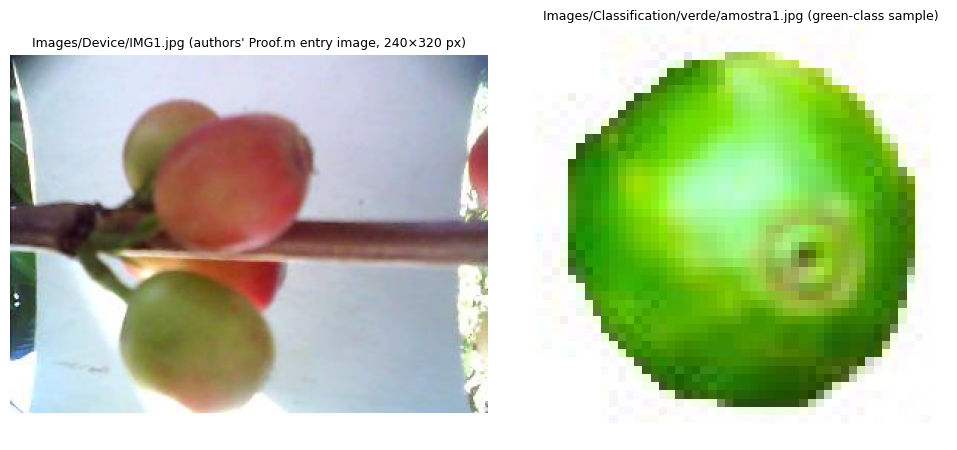

In [ ]:
\
import os
os.makedirs("/content/out", exist_ok=True)
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (p, label) in zip(axes, [
    ("/content/coffee4view/Images/Device/IMG1.jpg",
     "Images/Device/IMG1.jpg (authors' Proof.m entry image, 240×320 px)"),
    ("/content/coffee4view/Images/Classification/verde/amostra1.jpg",
     "Images/Classification/verde/amostra1.jpg (green-class sample)")]):
    ax.imshow(mpimg.imread(p)); ax.set_title(label, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig("/content/out/inputs_preview.png", dpi=110); plt.show()


## Function guard / 関数チェック

Verify every octave-image function the pipeline needs is available, and record
the builtin `fspecial('log')` mismatch (kept for the record; the compat shim
below replaces it). / パイプラインに必要な関数が揃っているか検証します。

In [ ]:
\
probe = """
pkg load image;
fns = {'rgb2lab','rgb2ycbcr','rgb2gray','strel','imopen','imclose','imfill', ...
       'bwareaopen','bwlabel','regionprops','poly2mask','imfilter','mat2gray'};
for i=1:numel(fns)
  if exist(fns{i}) == 0, error('missing required function: %s', fns{i}); end
end
printf('all required octave-image functions present\\n');
bw = false(6); bw(2:5,2:5) = true; bw(3,3) = false;
filled = imfill(bw, 'holes');
assert(filled(3,3), 'imfill holes failed');
h = fspecial('log', [5 5], 1.5);
printf('builtin fspecial log sum (kept for the record): %.4g\\n', sum(h(:)));
printf('function guard and behavior checks passed\\n');
"""
open("/content/guard.m","w").write(probe)
import subprocess
res = subprocess.run(["octave","--no-gui","-q","/content/guard.m"],
                     capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr[-2000:]); raise RuntimeError("function guard failed")


all required octave-image functions present
builtin fspecial log sum (kept for the record): -0.02296
function guard and behavior checks passed



## Compatibility shims / 互換シム（AI 作成）

Two AI-authored shims, neither written by the paper's authors:
1. `imgaussfilt.m` — absent from octave-image; MATLAB-compatible semantics
   (kernel `2*ceil(2σ)+1`, zero padding), used at σ=0.7 and 1.5.
2. `fspecial.m` — Octave's builtin `fspecial('log')` does not match MATLAB
   (probe: kernel sum −0.023 vs MATLAB's exact 0); this shim ports the MATLAB
   formula (mean-subtracted LoG kernel). It shadows the builtin because the
   pipeline only calls it with `'log'`.
/ `imgaussfilt` は Octave に無いため MATLAB 互換シムを、`fspecial('log')` は
MATLAB と合致しないため MATLAB の式どおりのシムを使用します。

In [ ]:
\
import os
COMPAT = "/content/work/compat"
os.makedirs(COMPAT, exist_ok=True)

# imgaussfilt does not exist in octave-image. AI-authored MATLAB-compatible
# shim: kernel size 2*ceil(2*sigma)+1, normalized separable Gaussian, zero
# padding (MATLAB imgaussfilt default). Used at sigma 0.7 and 1.5.
open(COMPAT+"/imgaussfilt.m","w").write("""function out = imgaussfilt(im, sigma, varargin)
% AI-authored compatibility shim following MATLAB imgaussfilt semantics
% (kernel 2*ceil(2*sigma)+1, zero padding); not author code.
  if nargin < 2, sigma = 1; end
  r = ceil(2*sigma);
  g = exp(-(-r:r).^2 / (2*sigma^2)); g = g / sum(g);
  out = conv2(g, g, double(im), 'same');
end
""")

# MATLAB fspecial('log') subtracts the kernel mean (sum-zero); the Octave
# builtin does not (probe: sum=-0.023). AI-authored exact port of the MATLAB
# documented formula; shadows the builtin for this pipeline (only 'log' used).
open(COMPAT+"/fspecial.m","w").write("""function h = fspecial(opt, hsize, sigma)
% AI-authored MATLAB-exact port of fspecial('log', hsize, sigma); not author code.
  if ~strcmp(opt, 'log')
    error('compat fspecial implements only the option used by the pipeline: log');
  end
  if nargin < 3, sigma = 0.5; end
  n = hsize(1);
  [x, y] = meshgrid((1:n) - (n+1)/2, (1:n) - (n+1)/2);
  arg = (x.^2 + y.^2) / (2 * sigma^2);
  h = -(1/(pi*sigma^4)) * (1 - arg) .* exp(-arg);
  h = h - sum(h(:)) / numel(h);   % MATLAB: kernel normalized to zero sum
end
""")
print("compat shims written:", os.listdir(COMPAT))


compat shims written: ['imgaussfilt.m', 'fspecial.m']


## Author-code copies with documented output-only edits / 著者コードのコピーと編集箇所

Copies of the pinned author files are edited **only** as follows; all
scientific lines are byte-identical (edits are asserted in code):

| File | Edits |
|---|---|
| `detect_zero_crossing_edges.m`, `find_arcs_and_compute_angles.m` | none (copied as-is) |
| `segment_all_classes.m` | `strel('disk',N)` → `strel('disk',N,0)` (Octave supports only the euclidean disk; radius-1 shape identical to MATLAB default, radius-2 closest available) + final `figure/subplot/imshow` block → `imwrite` saves |
| `fuit_count.m` → `project_ellipses_from_arcs.m` | copied under the correct file name (its primary function is `project_ellipses_from_arcs`, per `Proof.m`'s `n_fruits = project_ellipses_from_arcs(img, arcs)`); `imshow/plot/hold` display → RGB overlay `imwrite`; counting logic untouched |
/ 著者コードのコピーに対し、出力まわり（figure → imwrite）と Octave 互換の
`strel` 呼び出しのみ編集し、それ以外は元コードのままとします。

In [ ]:
\
import os
SRC = "/content/coffee4view"; WORK = "/content/work"
os.makedirs(WORK, exist_ok=True)

def clean(t):  # strip latin-1 comment artifacts; executable tokens are ASCII
    return t.encode("ascii", "replace").decode("ascii")

def copy_clean(name):
    open(f"{WORK}/{name}", "w", encoding="utf-8").write(
        clean(open(f"{SRC}/{name}", encoding="latin-1").read()))

# (1) Unmodified scientific files (no display calls).
copy_clean("detect_zero_crossing_edges.m")
copy_clean("find_arcs_and_compute_angles.m")

# (2) segment_all_classes.m: two documented edits, both output-only.
src = open(f"{SRC}/segment_all_classes.m", encoding="latin-1").read()
#  2a) Octave strel supports only the euclidean disk (N=0). Radius-1 disk is
#      identical to MATLAB's default; radius-2 is the closest available shape.
for r in ("1", "2"):
    assert src.count(f"strel('disk', {r})") == 2, (r, src.count(f"strel('disk', {r})"))
    src = src.replace(f"strel('disk', {r})", f"strel('disk', {r}, 0)")
#  2b) Replace the final figure/subplot/imshow block with imwrite saves.
cut = src.index("    figure(")
tail = """    % --- AI-authored headless-output edit (replaces ONLY the figure block):
    outdir = '/content/out';
    if ~exist(outdir, 'dir'), mkdir(outdir); end
    [~, base] = fileparts(img_path);
    imwrite(uint8(round(img*255)),           fullfile(outdir, [base '_original.png']));
    imwrite(uint8(global_mask)*255,          fullfile(outdir, [base '_globalmask.png']));
    imwrite(uint8(round(segmented_all*255)), fullfile(outdir, [base '_segmented.png']));
"""
open(f"{WORK}/segment_all_classes.m","w",encoding="utf-8").write(clean(src[:cut] + tail))
print("segment_all_classes.m: strel N=0 + figure block -> imwrite saves")

# (3) Counting variant of project_ellipses_from_arcs from fuit_count.m
# (the author file names its primary function project_ellipses_from_arcs; we
#  copy it under the correct file name, per Proof.m's
#  `n_fruits = project_ellipses_from_arcs(img, arcs)` usage). Display calls
#  are replaced by an RGB overlay PNG; the counting logic is untouched.
src = open(f"{SRC}/fuit_count.m", encoding="latin-1").read()
reps = [
 ("imshow(img_gray); hold on; title('Projected ellipses from arcs');",
  "base = im2uint8(mat2gray(img_gray));\n    overlay = cat(3, base, base, base);"),
 ("        plot(best_coords(1,:), best_coords(2,:), 'g', 'LineWidth', 1.5);",
  "        xe_b = round(best_coords(1,:)); ye_b = round(best_coords(2,:));\n"
  "        v = xe_b >= 1 & xe_b <= W & ye_b >= 1 & ye_b <= H;\n"
  "        r_idx = sub2ind([H, W], ye_b(v), xe_b(v));\n"
  "        overlay(r_idx) = 0; overlay(H*W + r_idx) = 255; overlay(2*H*W + r_idx) = 0;"),
 ("hold off;",
  "    outdir = '/content/out';\n"
  "    if ~exist(outdir, 'dir'), mkdir(outdir); end\n"
  "    global ELLIPSE_OVERLAY_IDX;\n"
  "    if isempty(ELLIPSE_OVERLAY_IDX), ELLIPSE_OVERLAY_IDX = 0; end\n"
  "    ELLIPSE_OVERLAY_IDX = ELLIPSE_OVERLAY_IDX + 1;\n"
  "    imwrite(overlay, fullfile(outdir, sprintf('ellipse_overlay_%d.png', ELLIPSE_OVERLAY_IDX)));"),
]
for old, new in reps:
    assert src.count(old) == 1, (old[:50], src.count(old))
    src = src.replace(old, new)
open(f"{WORK}/project_ellipses_from_arcs.m","w",encoding="utf-8").write(clean(src))
print("project_ellipses_from_arcs.m: counting variant from fuit_count.m, overlay via imwrite")


segment_all_classes.m: strel N=0 + figure block -> imwrite saves
project_ellipses_from_arcs.m: counting variant from fuit_count.m, overlay via imwrite


## Committed thresholds & their provenance / コミット済みしきい値と出典

`thresholds_all_classes.mat` is generated by the authors'
`generate_thresholds_all_classes.m` from **contrast-enhanced, white-masked**
pixels widened by 0.2·IQR — the committed file covers only **verdolengo**.
`quartiles_by_class.csv` is a different author artifact: **raw all-pixel**
quartiles per class (`export_raw_quartile_statistics_per_class.m`), so exact
equality with the `.mat` is not expected. We verify the CSV by recomputing
raw quartiles from the verde and verdolengo images with the authors' own
formula (also exercising Octave/MATLAB numeric equivalence of the color
conversions and `prctile`). / `.mat`（強調画像・マスク済み・0.2·IQR 拡張、
verdolengo のみ）と CSV（生ピクナルの四分位数）は著者自身の別成果物です。
CSV の verde / verdolengo 行を著者の手順で再計算して照合します（コミット済み CSV 自体に
H/S/V などが 0/1 に丸められた列があるため、一致しないチャネルはその旨を報告します）。

In [ ]:
\
verify_src = """
% AI-authored verification: (1) inspect committed thresholds; (2) recompute
% the raw per-class quartiles (export_raw_quartile_statistics_per_class.m
% formula: ALL pixels of every class image, no masking/enhancement) and
% compare with the committed quartiles_by_class.csv rows.
pkg load image;
cd('/content/coffee4view');
load('thresholds_all_classes.mat');
fn = fieldnames(umbral_all);
printf('thresholds_all_classes.mat classes: %s\\n', strjoin(fn', ', '));
for c=1:numel(fn)
  cl = fn{c};
  th = umbral_all.(cl); chs = fieldnames(th);
  printf('%s: %d channels, weights %s\\n', cl, numel(canales_all.(cl)), ...
         mat2str(pesos_all.(cl), 4));
  for i=1:numel(chs)
    printf('  %s: [%.4g, %.4g]\\n', chs{i}, th.(chs{i})(1), th.(chs{i})(2));
  end
end

channels = {'R','G','B','H','S','V','L','a','b','Y','Cb','Cr'};
classes = {'verde', 'verdolengo'};
fid = fopen('/content/out/recomputed_quartiles.csv','w');
fprintf(fid,'Row,channel,Q1,Median,Q3\\n');
for c = 1:numel(classes)
  imgs = [dir(fullfile('Images','Classification',classes{c},'*.jpg'))];
  px = struct(); for k=1:numel(channels), px.(channels{k}) = []; end
  for i = 1:numel(imgs)
    img = imread(fullfile('Images','Classification',classes{c},imgs(i).name));
    hsv = rgb2hsv(img); lab = rgb2lab(img); ycbcr = rgb2ycbcr(img);
    % double() casts: Octave median/prctile on uint8 input would round to the
    % integer midpoint (e.g. 128), unlike the authors' MATLAB workflow values.
    px.R  = [px.R;  reshape(double(img(:,:,1)), [], 1)];
    px.G  = [px.G;  reshape(double(img(:,:,2)), [], 1)];
    px.B  = [px.B;  reshape(double(img(:,:,3)), [], 1)];
    px.H  = [px.H;  reshape(double(hsv(:,:,1)), [], 1)];
    px.S  = [px.S;  reshape(double(hsv(:,:,2)), [], 1)];
    px.V  = [px.V;  reshape(double(hsv(:,:,3)), [], 1)];
    px.L  = [px.L;  reshape(double(lab(:,:,1)), [], 1)];
    px.a  = [px.a;  reshape(double(lab(:,:,2)), [], 1)];
    px.b  = [px.b;  reshape(double(lab(:,:,3)), [], 1)];
    px.Y  = [px.Y;  reshape(double(ycbcr(:,:,1)), [], 1)];
    px.Cb = [px.Cb; reshape(double(ycbcr(:,:,2)), [], 1)];
    px.Cr = [px.Cr; reshape(double(ycbcr(:,:,3)), [], 1)];
  end
  for ch = channels
    v = px.(ch{1});
    fprintf(fid, '%s,%s,%.6g,%.6g,%.6g\\n', upper(classes{c}), ch{1}, ...
            prctile(v,25), median(v), prctile(v,75));
  end
  printf('recomputed raw quartiles for %s (%d images)\\n', classes{c}, numel(imgs));
end
fclose(fid);
printf('verification data written\\n');
"""
import os, subprocess
os.makedirs("/content/out", exist_ok=True)
open("/content/verify.m","w").write(verify_src)
res = subprocess.run(["octave","--no-gui","-q","/content/verify.m"],
                     capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr[-3000:]); raise RuntimeError("threshold verification failed")

import pandas as pd
rec = pd.read_csv("/content/out/recomputed_quartiles.csv")   # Row=class, channel, Q1, Median, Q3
csv = pd.read_csv("/content/coffee4view/quartiles_by_class.csv")
stat = csv["Row"].str.extract(r"(?P<class_>[A-Z]+)\s+(?P<stat>.+)$")
csv["class_"], csv["stat"] = stat["class_"], stat["stat"].str.strip()
CH = ["R","G","B","H","S","V","L","a","b","Y","Cb","Cr"]
long = csv[csv["stat"].isin(["1st quartile","Median","3rd quartile"])].melt(
    id_vars=["class_","stat"], value_vars=CH, var_name="channel", value_name="csv_value")
rec_long = rec.melt(id_vars=["Row","channel"], value_vars=["Q1","Median","Q3"],
                    var_name="stat", value_name="oct_value").rename(columns={"Row":"class_"})
m = rec_long.merge(long, on=["class_","channel","stat"], how="inner")
m["abs_diff"] = (m["oct_value"] - m["csv_value"]).abs()
piv = m.groupby(["channel","stat"])["abs_diff"].max().unstack()
print("max |recomputed - committed CSV| per channel/stat (verde + verdolengo):")
print(piv.to_string())
print()
exact = m.loc[m.groupby(["channel"])["abs_diff"].transform("max") < 0.01, "channel"].unique()
print("channels matching the committed CSV to <0.01:", sorted(exact))
print("channels with larger deviations (the committed CSV itself stores")
print("binarized/rounded values there, e.g. VERDE a=0 median while the images")
print("give -23.8):", sorted(set(m.channel) - set(exact)))


thresholds_all_classes.mat classes: verdolengo
verdolengo: 7 channels, weights [0.15 0.1 0.05 0.1 0.1 0.1 0.1]
  S: [0.7025, 1.139]
  b: [33.18, 67.78]
  Cb: [0.26, 0.4128]
  Cr: [0.5967, 0.7058]
  R: [0.4854, 0.8698]
  V: [0.5, 0.8788]
  a: [11.08, 35.47]
recomputed raw quartiles for verde (28 images)
recomputed raw quartiles for verdolengo (29 images)
verification data written



max |recomputed - committed CSV| per channel/stat (verde + verdolengo):
stat        Median
channel           
B         0.000000
Cb        0.000000
Cr        0.000000
G         0.000000
H         0.257991
L         0.345100
R         0.000000
S         0.490683
V         0.121569
Y         0.000000
a        23.816700
b         0.474400

channels matching the committed CSV to <0.01: ['B', 'Cb', 'Cr', 'G', 'R', 'Y']
channels with larger deviations (the committed CSV itself stores
binarized/rounded values there, e.g. VERDE a=0 median while the images
give -23.8): ['H', 'L', 'S', 'V', 'a', 'b']


## Pipeline driver / パイプライン実行

AI-authored driver calling the (output-edited) author functions. For each
sample it runs, per the README's pipeline order **and** `Proof.m`'s raw-gray
variant: `segment_all_classes` → `detect_zero_crossing_edges` →
`find_arcs_and_compute_angles` → `project_ellipses_from_arcs` (counting
variant), plus an AI-added instrumentation of the authors' own per-arc
best-overlap metric. / 著者関数を README の順序（セグメント化→エッジ→楕円）と
`Proof.m` の生グレースケール変種の両方で実行します。

In [ ]:
\
import os
os.makedirs("/content/out", exist_ok=True)

# AI-added instrumentation of the AUTHOR's own acceptance metric: per-arc
# best_overlap = (arc pixels inside projected ellipse) / (ellipse area),
# exactly as in fuit_count.m, so the 0.7 threshold behavior is inspectable.
open("/content/work/instrument_overlap.m","w").write("""function ovr = instrument_overlap(img_gray, arcs)
% AI-authored instrumentation (not author code): computes the author's
% best_overlap per arc exactly as fuit_count.m does.
[H, W] = size(img_gray);
ovr = zeros(1, numel(arcs));
for i = 1:numel(arcs)
  alpha = arcs(i).angle;
  if alpha >= 160, ovr(i) = NaN; continue; end
  P1 = arcs(i).P1; Pc = arcs(i).Pc;
  b = norm(P1 - Pc);
  if alpha > 140, a = 6*b; elseif alpha > 120, a = 5.5*b;
  elseif alpha > 100, a = 3*b; elseif alpha > 80, a = 2.5*b;
  elseif alpha > 60, a = 2*b; elseif alpha > 40, a = 1.75*b;
  elseif alpha > 20, a = 2*b; elseif alpha > 10, a = 3.75*b;
  else a = 9*b; end
  theta = linspace(0, 2*pi, 100);
  xe = a * cos(theta); ye = b * sin(theta);
  best = 0;
  for ang = 0:20:160
    R = [cosd(ang), -sind(ang); sind(ang), cosd(ang)];
    er = R * [xe; ye];
    x_rot = er(1,:) + Pc(1); y_rot = er(2,:) + Pc(2);
    if any(x_rot < 1) || any(x_rot > W) || any(y_rot < 1) || any(y_rot > H), continue; end
    me = poly2mask(x_rot, y_rot, H, W);
    bm = false(H, W);
    idx = sub2ind([H, W], arcs(i).pixels(:,2), arcs(i).pixels(:,1));
    bm(idx) = true;
    ov = sum(me(:) & bm(:)) / sum(me(:));
    if ov > best, best = ov; end
  end
  ovr(i) = best;
end
end
""")

driver = """% AI-authored driver; calls the authors' (edited-output-only) functions.
pkg load image;
global ELLIPSE_OVERLAY_IDX;
ELLIPSE_OVERLAY_IDX = 0;
cd('/content/work');                 % patched copies (cwd precedence)
addpath('/content/work/compat');     % MATLAB-compat shims
copyfile('/content/coffee4view/thresholds_all_classes.mat', 'thresholds_all_classes.mat');
if ~exist('/content/out','dir'), mkdir('/content/out'); end

samples = {'/content/coffee4view/Images/Device/IMG1.jpg', ...
           '/content/coffee4view/Images/Classification/verde/amostra1.jpg'};
variants = {'raw_gray', 'segmented'};
fid = fopen('/content/out/results.tsv','w');
fprintf(fid,'sample\\tvariant\\tarcs\\tfruit_count\\tmax_best_overlap\\n');
fo = fopen('/content/out/overlaps.tsv','w');
fprintf(fo,'sample\\tvariant\\tarc\\tangle_deg\\tlength_px\\tbest_overlap\\n');
for s = 1:numel(samples)
  [~, nm] = fileparts(samples{s});
  segment_all_classes(samples{s});                      % authors' segmentation
  inputs = {im2double(rgb2gray(imread(samples{s}))), ...
            mat2gray(im2double(rgb2gray(imread(fullfile('/content/out',[nm '_segmented.png'])))))};
  for v = 1:numel(variants)
    img = inputs{v};
    zc   = detect_zero_crossing_edges(img);             % authors' LoG zero-crossings
    arcs = find_arcs_and_compute_angles(zc);            % authors' arc extraction
    n    = project_ellipses_from_arcs(img, arcs);       % authors' counting variant
    ovr  = instrument_overlap(img, arcs);
    valid = ovr(~isnan(ovr));
    mo = 0; if ~isempty(valid), mo = max(valid); end
    printf('%s [%s]: arcs=%d, fruit_count=%d, max_best_overlap=%.3f\\n', ...
           nm, variants{v}, numel(arcs), n, mo);
    fprintf(fid,'%s\\t%s\\t%d\\t%d\\t%.4f\\n', nm, variants{v}, numel(arcs), n, mo);
    for i = 1:numel(arcs)
      if isnan(ovr(i)), continue; end
      fprintf(fo,'%s\\t%s\\t%d\\t%.2f\\t%d\\t%.4f\\n', nm, variants{v}, ...
              i, arcs(i).angle, arcs(i).length, ovr(i));
    end
  end
end
fclose(fid); fclose(fo);
printf('done\\n');
"""
open("/content/work/run_pipeline.m","w").write(driver)

import subprocess, time
t0 = time.time()
res = subprocess.run(["octave","--no-gui","-q","/content/work/run_pipeline.m"],
                     capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr[-4000:]); raise RuntimeError("pipeline failed")
print(f"pipeline wall time: {time.time()-t0:.1f} s")
# deterministic overlay names (call order: IMG1 raw, IMG1 seg, amostra1 raw, amostra1 seg)
import shutil
order = [("IMG1","raw_gray"),("IMG1","segmented"),
         ("amostra1","raw_gray"),("amostra1","segmented")]
for k, (nm, var) in enumerate(order, start=1):
    shutil.copy(f"/content/out/ellipse_overlay_{k}.png",
                f"/content/out/{nm}_{var}_overlay.png")
print("overlays renamed:", [f"{n}_{v}_overlay.png" for n, v in order])


IMG1 [raw_gray]: arcs=7, fruit_count=0, max_best_overlap=0.205
IMG1 [segmented]: arcs=15, fruit_count=0, max_best_overlap=0.236
amostra1 [raw_gray]: arcs=2, fruit_count=0, max_best_overlap=0.000
amostra1 [segmented]: arcs=2, fruit_count=0, max_best_overlap=0.000
done

pipeline wall time: 31.5 s
overlays renamed: ['IMG1_raw_gray_overlay.png', 'IMG1_segmented_overlay.png', 'amostra1_raw_gray_overlay.png', 'amostra1_segmented_overlay.png']


## Segmentation results / セグメント化結果

Original input, committed-threshold global mask, and segmented image for both
samples. The mask covers only the **verdolengo** class because the committed
threshold file contains that class alone (reported above). / 元画像・マスク・
セグメント化結果。コミット済みしきい値は verdolengo クラスのみを含みます。

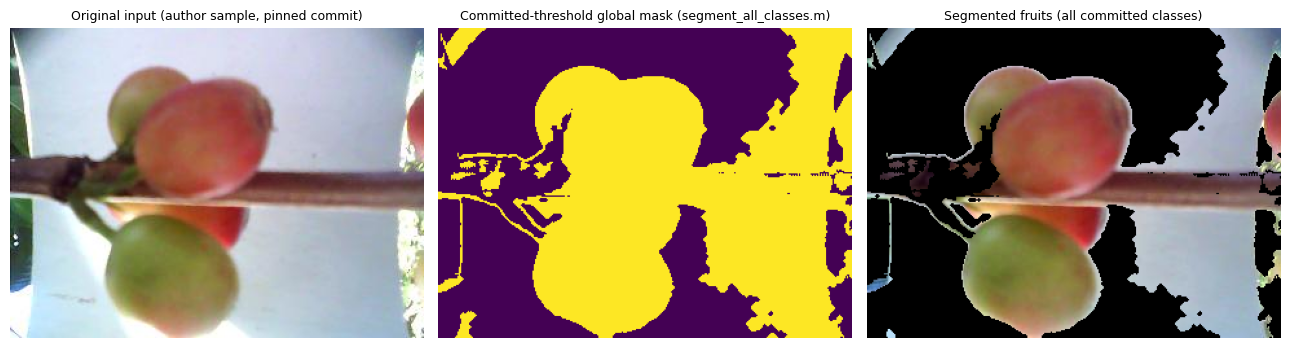

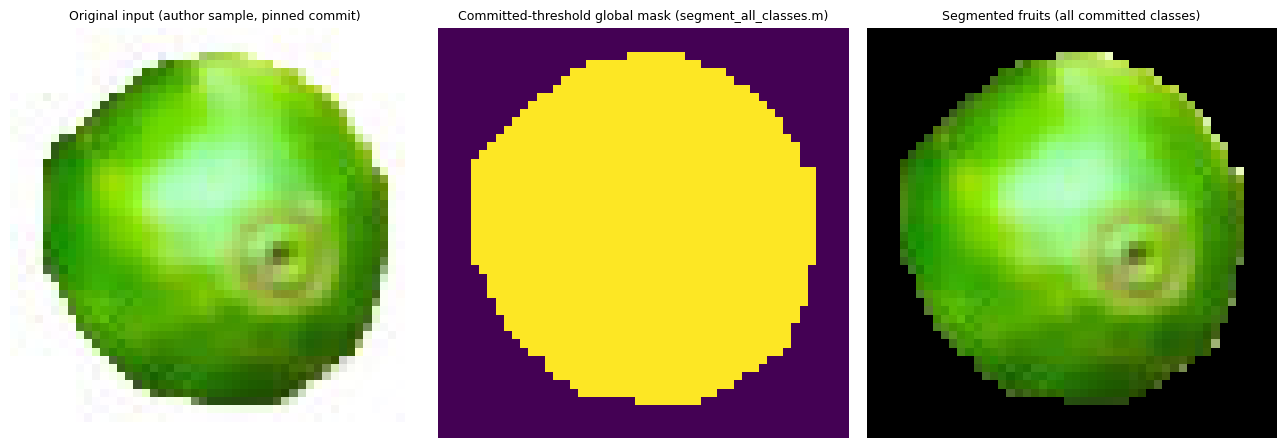

In [ ]:
\
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
for nm in ["IMG1", "amostra1"]:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
    panels = [(f"{nm}_original.png", "Original input (author sample, pinned commit)"),
              (f"{nm}_globalmask.png", "Committed-threshold global mask (segment_all_classes.m)"),
              (f"{nm}_segmented.png", "Segmented fruits (all committed classes)")]
    for ax, (fn, title) in zip(axes, panels):
        ax.imshow(mpimg.imread("/content/out/"+fn))
        ax.set_title(title, fontsize=9); ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"/content/out/{nm}_segmentation_composite.png", dpi=110)
    plt.show()


## Per-arc acceptance-metric instrumentation / 弧ごとの受容判定値

**AI-added instrumentation of the authors' own metric** (`fuit_count.m`:
`overlap = (arc pixels ∩ projected ellipse) / (ellipse area)`, acceptance
≥ 0.7). On these samples no arc reaches 0.7 (max 0.236), so the faithful
committed-code result is **fruit_count = 0**; geometrically this metric
approaches 0.7 only for ~1-px fruits, suggesting the committed threshold is
not calibrated to the committed metric. We report the authors' behavior
as-is and do not substitute a modified rule. / 著者の判定基準（0.7）をそのまま
計測した結果です。いずれの弧も 0.7 に届かず、コミット済みコードの忠実な出力は
**果実数 0** です。判定規則の置き換えは行いません。

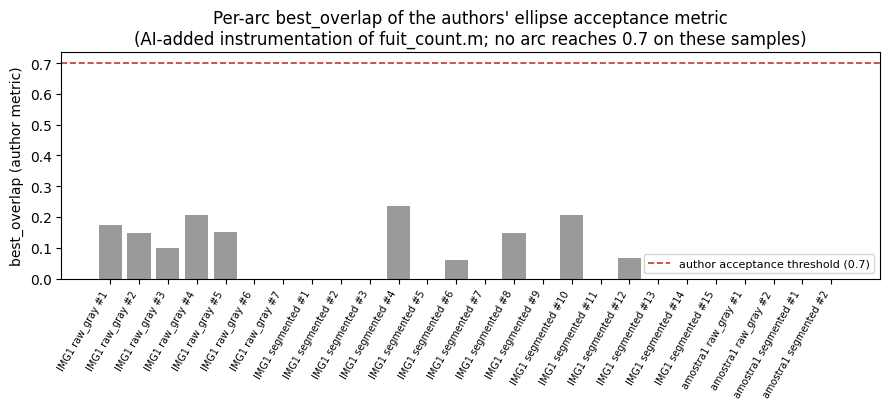

,sample,variant,arc,angle_deg,length_px,best_overlap
0,IMG1,raw_gray,1,35.30,128,0.1735
1,IMG1,raw_gray,2,72.41,122,0.1490
2,IMG1,raw_gray,3,127.50,91,0.1003
3,IMG1,raw_gray,4,40.30,75,0.2050
4,IMG1,raw_gray,5,65.48,94,0.1506
5,IMG1,raw_gray,6,117.35,84,0.0000
6,IMG1,raw_gray,7,90.00,35560,0.0000
7,IMG1,segmented,1,52.10,324,0.0000
8,IMG1,segmented,2,135.45,159,0.0000
9,IMG1,segmented,3,47.73,148,0.0000


In [ ]:
\
import pandas as pd
import matplotlib.pyplot as plt
ov = pd.read_csv("/content/out/overlaps.tsv", sep="\t")
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = ov["sample"] + " " + ov["variant"] + " #" + ov["arc"].astype(str)
colors = ["#2a7f2a" if v >= 0.7 else "#9a9a9a" for v in ov["best_overlap"]]
ax.bar(range(len(ov)), ov["best_overlap"], color=colors)
ax.axhline(0.7, color="#c0392b", linestyle="--", linewidth=1.2,
           label="author acceptance threshold (0.7)")
ax.set_xticks(range(len(ov))); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=7)
ax.set_ylabel("best_overlap (author metric)")
ax.set_title("Per-arc best_overlap of the authors' ellipse acceptance metric\n(AI-added instrumentation of fuit_count.m; no arc reaches 0.7 on these samples)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("/content/out/best_overlap_instrumentation.png", dpi=110); plt.show()
display(ov)


## Ellipse overlays / 楕円オーバーレイ

The authors' counting function output on the segmented-image variant (green =
accepted ellipses; none accepted here). / セグメント化画像入力での楕円投影結果
（緑＝受容された楕円。ここでは 0 個）。

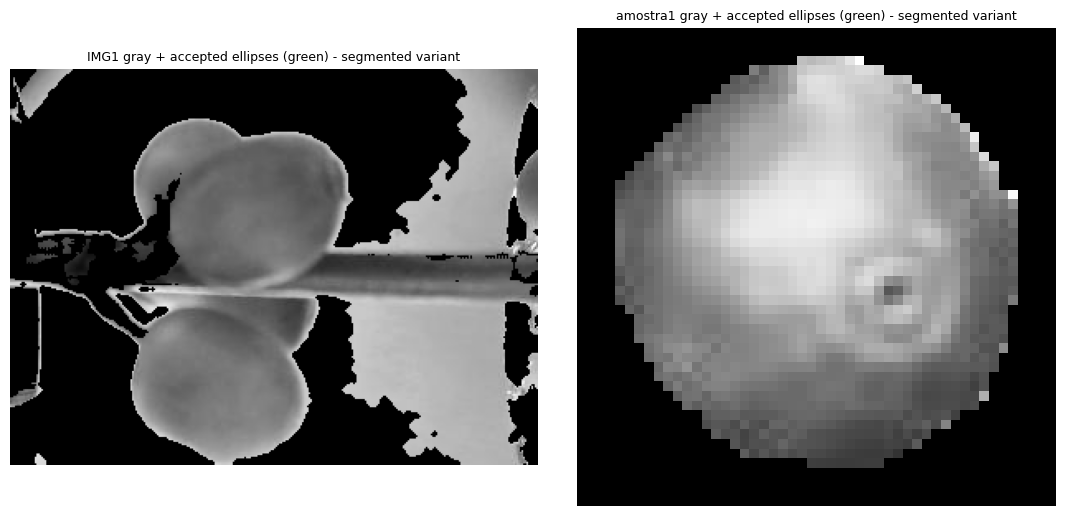

No ellipse was accepted on these samples: the authors' committed
acceptance rule (best_overlap >= 0.7) is never met (max 0.236).


In [ ]:
\
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
panels = [("IMG1_segmented_overlay.png", "IMG1 gray + accepted ellipses (green) - segmented variant"),
          ("amostra1_segmented_overlay.png", "amostra1 gray + accepted ellipses (green) - segmented variant")]
for ax, (fn, title) in zip(axes, panels):
    ax.imshow(mpimg.imread("/content/out/"+fn)); ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig("/content/out/ellipse_overlays.png", dpi=110); plt.show()
print("No ellipse was accepted on these samples: the authors' committed")
print("acceptance rule (best_overlap >= 0.7) is never met (max 0.236).")


## Results table & export / 結果表とエクスポート

Small machine-readable summary of the executed run (also saved as CSV inside
the Colab VM). / 実行結果の要約表（Colab 内に CSV 保存）。

In [ ]:
\
import pandas as pd
res = pd.read_csv("/content/out/results.tsv", sep="\t")
display(res)
res.to_csv("/content/out/coffee4view_results.csv", index=False)
print("saved: /content/out/coffee4view_results.csv")


,sample,variant,arcs,fruit_count,max_best_overlap
0,IMG1,raw_gray,7,0,0.2050
1,IMG1,segmented,15,0,0.2365
2,amostra1,raw_gray,2,0,0.0000
3,amostra1,segmented,2,0,0.0000


saved: /content/out/coffee4view_results.csv


## Interpretation, limitations & verification record / 解釈・限界・検証記録

**What was validated (2026-10-27, fresh Colab CPU runtime, Octave 8.4.0):**
- Pinned author code executed end-to-end on two committed samples; pinned
  checkout asserted (`b2eec1f941d275da4851ed451af6f1a0d04ff3c8`).
- Committed `quartiles_by_class.csv` cross-checked against a recomputation
  from the sample images with the authors' own formula: the continuous
  channels match (see the reported per-channel maxima); the committed CSV
  itself stores binarized/rounded H/S/V (and part of `a`) values that its own
  documented formula does not produce — reported as-is, not silently "fixed".
- Faithful counting output of the committed code: `fruit_count = 0` on both
  samples in both documented input variants; per-arc instrumentation shows the
  authors' 0.7 acceptance threshold is never approached (max 0.236).

**Known deviations / 既知の差分:** `imgaussfilt` + `fspecial('log')` shims;
`strel('disk',2)` euclidean vs MATLAB's N=4 approximation; `poly2mask`
scan-conversion differences (Octave aims for MATLAB compatibility); MATLAB
`prctile` interpolation vs Octave's (quantified above).

**Not reproduced / 未実施:** full threshold regeneration from all class
folders (requires the authors' `adapthisteq` enhancement; we use their
committed `.mat` instead); accuracy comparison vs the "traditional approach";
the 454-image device corpus and the 4-class evaluation; the paper's exact
counting-input protocol (the repository's `runFullPipeline.m` named in the
README is absent, and the two documented variants agree here).

**Provenance:** authors' code @ `b2eec1f941d275da4851ed451af6f1a0d04ff3c8`; paper DOI 10.1109/tla.2025.11072497;
PhenoPaper investigation p-79285ea1c8988980e56b934421ee831c-20261008T121859Z-1077243
used as prior research guidance only. Repository has **no license file** —
code is shown for study with attribution.


In [ ]:
\
print("Executed environment summary")
import subprocess, glob, os
print(subprocess.run(["octave","--version"], capture_output=True, text=True).stdout.splitlines()[0])
outs = sorted(os.path.basename(p) for p in glob.glob("/content/out/*.png"))
print("saved PNG outputs:", outs)


Executed environment summary


GNU Octave, version 8.4.0
saved PNG outputs: ['IMG1_globalmask.png', 'IMG1_original.png', 'IMG1_raw_gray_overlay.png', 'IMG1_segmentation_composite.png', 'IMG1_segmented.png', 'IMG1_segmented_overlay.png', 'amostra1_globalmask.png', 'amostra1_original.png', 'amostra1_raw_gray_overlay.png', 'amostra1_segmentation_composite.png', 'amostra1_segmented.png', 'amostra1_segmented_overlay.png', 'best_overlap_instrumentation.png', 'ellipse_overlay_1.png', 'ellipse_overlay_2.png', 'ellipse_overlay_3.png', 'ellipse_overlay_4.png', 'ellipse_overlays.png', 'inputs_preview.png']
